# Lab 03-04 · Joint Distributions, Correlation and the CLT

Companion to chapter [03-04](../../chapters/03-04-joint-distributions-and-clt.md). Handout: [README.md](README.md).

Each part generates dependent or summed random variables and compares them with the chapter's formulas. Cells marked **🔮 Predict** ask you to write a prediction *before* running. The seed is fixed, so your numbers will match the handout's.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
rng = np.random.default_rng(2026)
Q = stats.norm.sf

## Part 1 — A joint distribution from data

Draw 200,000 neighboring-die pairs from the joint PMF of Example 03-04.1 and estimate the joint table, the marginals, the conditional probability and the covariance from the samples alone.

In [2]:
outcomes = np.array([(0, 0), (1, 0), (0, 1), (1, 1)])
idx = rng.choice(4, 200_000, p=[0.85, 0.05, 0.05, 0.05])
X, Y = outcomes[idx, 0], outcomes[idx, 1]
table = np.array([[np.mean((X == i) & (Y == j)) for j in (0, 1)] for i in (0, 1)])
print("estimated joint PMF (rows X, columns Y):\n", table.round(4))
print(f"P(X=1) = {X.mean():.4f}, P(Y=1 | X=1) = {Y[X == 1].mean():.4f}")
cov = np.mean(X * Y) - X.mean() * Y.mean()
print(f"covariance {cov:.4f} (theory 0.04), correlation {np.corrcoef(X, Y)[0, 1]:.4f} (theory 0.4444)")

estimated joint PMF (rows X, columns Y):
 [[0.8517 0.0501]
 [0.0486 0.0496]]
P(X=1) = 0.0982, P(Y=1 | X=1) = 0.5048
covariance 0.0398 (theory 0.04), correlation 0.4462 (theory 0.4444)


## Part 2 — Correlated noise and differential receivers

To make two Gaussian noises with correlation ρ, multiply independent standard normals by a **Cholesky factor** $L$ of the covariance matrix $\Sigma = LL^T$ ([02-06](../../../02-complex-numbers-des-and-linear-algebra/chapters/02-06-vectors-matrices-and-linear-systems.md)). Then measure the differential noise.

**🔮 Predict:** at ρ = 0.9, how large is the differential noise compared with one wire's?

In [3]:
sigma = 10.0                                   # mV per wire
for rho in (-0.5, 0.0, 0.5, 0.9, 0.99):
    Sigma = sigma**2 * np.array([[1, rho], [rho, 1]])
    L = np.linalg.cholesky(Sigma)
    n = L @ rng.standard_normal((2, 400_000))
    d = n[0] - n[1]
    print(f"rho = {rho:5.2f}: measured {d.std():6.3f} mV   theory {sigma * math.sqrt(2 * (1 - rho)):6.3f} mV")

rho = -0.50: measured 17.320 mV   theory 17.321 mV
rho =  0.00: measured 14.149 mV   theory 14.142 mV
rho =  0.50: measured  9.996 mV   theory 10.000 mV
rho =  0.90: measured  4.473 mV   theory  4.472 mV
rho =  0.99: measured  1.414 mV   theory  1.414 mV


## Part 3 — Convolution

The density of a sum of independent variables is the convolution of their densities. Compare a histogram of $U_1 + U_2 + U_3$ (each uniform on $[-1/2, 1/2]$) with a numerical convolution and with a Gaussian of the same variance.

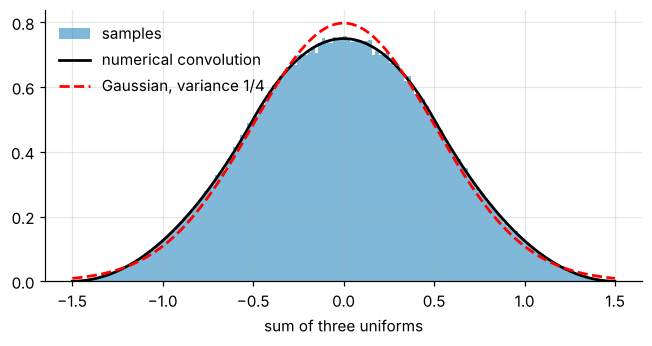

density at 0: convolution 0.7500 (exact 0.75), Gaussian 0.7979
variance of two-term sum: 0.1664 (theory 1/6 = 0.1667)


In [4]:
dx = 0.001
x = np.arange(-0.5, 0.5, dx) + dx / 2
f = np.ones_like(x)                            # uniform density on [-1/2, 1/2]
f2 = np.convolve(f, f) * dx
f3 = np.convolve(f2, f) * dx
z3 = (np.arange(f3.size) - (f3.size - 1) / 2) * dx
s = rng.uniform(-0.5, 0.5, (3, 500_000)).sum(0)
plt.figure(figsize=(7, 3.2))
plt.hist(s, bins=150, density=True, alpha=0.5, label="samples")
plt.plot(z3, f3, "k", label="numerical convolution")
plt.plot(z3, stats.norm.pdf(z3, 0, 0.5), "r--", label="Gaussian, variance 1/4")
plt.legend(); plt.xlabel("sum of three uniforms"); plt.show()
print(f"density at 0: convolution {f3[np.argmin(abs(z3))]:.4f} (exact 0.75), Gaussian {stats.norm.pdf(0, 0, 0.5):.4f}")
print(f"variance of two-term sum: {rng.uniform(-0.5, 0.5, (2, 500_000)).sum(0).var():.4f} (theory 1/6 = {1 / 6:.4f})")

## Part 4 — The CLT and its tails

Sums of exponentials are skewed. Standardize the sum of $n$ exponentials and compare its distribution with the Gaussian.

**🔮 Predict:** with $n = 30$, is $P(Z > 3)$ above or below $Q(3) = 0.00135$? By how much?

In [5]:
for n in (1, 5, 30, 200):
    S = rng.exponential(1.0, (n, 200_000)).sum(0) if n <= 30 else rng.gamma(n, 1.0, 200_000)
    Z = (S - n) / math.sqrt(n)
    exact = stats.gamma.sf(n + 3 * math.sqrt(n), n)
    print(f"n = {n:3d}: skewness {stats.skew(Z):5.2f}   P(Z > 3): sampled {np.mean(Z > 3):.5f}, exact {exact:.5f}, Q(3) {Q(3):.5f}")

n =   1: skewness  1.99   P(Z > 3): sampled 0.01829, exact 0.01832, Q(3) 0.00135
n =   5: skewness  0.89   P(Z > 3): sampled 0.00921, exact 0.00931, Q(3) 0.00135
n =  30: skewness  0.36   P(Z > 3): sampled 0.00425, exact 0.00416, Q(3) 0.00135
n = 200: skewness  0.14   P(Z > 3): sampled 0.00228, exact 0.00230, Q(3) 0.00135


The skewness falls like $2/\sqrt n$ and the center becomes Gaussian, but at $3\sigma$ the right tail is still about three times heavier than $Q(3)$ at $n = 30$. Deeper in the tail the ratio grows: the CLT is a statement about the center.

## Part 5 — Polar form of a complex Gaussian

Draw independent I and Q noise with σ = 1 and convert to envelope and phase.

**🔮 Predict:** the mean envelope, and whether the envelope and phase are correlated.

mean envelope 1.2540 (theory sqrt(pi/2) = 1.2533)
mean power 2.0020 (theory 2), P(R > 3) = 0.01132 (theory 0.01111)


correlation of R with phase: 0.0000; with |phase|: -0.0003


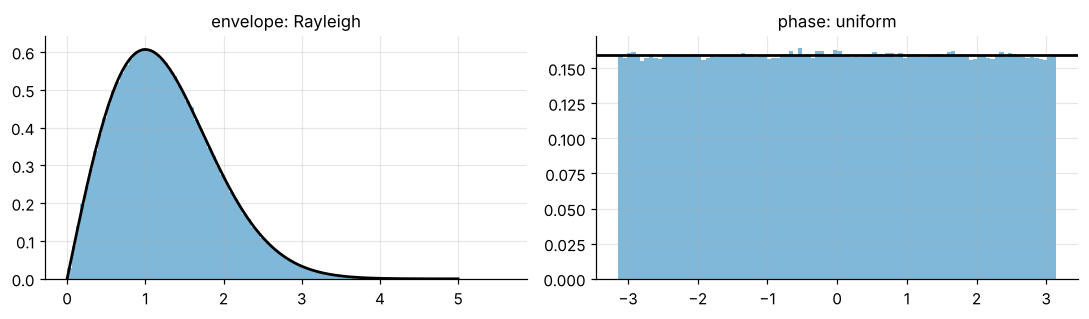

In [6]:
I, Qn = rng.standard_normal((2, 1_000_000))
R, Th = np.hypot(I, Qn), np.arctan2(Qn, I)
print(f"mean envelope {R.mean():.4f} (theory sqrt(pi/2) = {math.sqrt(math.pi / 2):.4f})")
print(f"mean power {np.mean(R**2):.4f} (theory 2), P(R > 3) = {np.mean(R > 3):.5f} (theory {math.exp(-4.5):.5f})")
print(f"correlation of R with phase: {np.corrcoef(R, Th)[0, 1]:.4f}; with |phase|: {np.corrcoef(R, abs(Th))[0, 1]:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
r = np.linspace(0, 5, 200)
ax[0].hist(R, bins=100, density=True, alpha=0.5); ax[0].plot(r, r * np.exp(-r**2 / 2), "k"); ax[0].set_title("envelope: Rayleigh")
ax[1].hist(Th, bins=100, density=True, alpha=0.5); ax[1].axhline(1 / (2 * math.pi), color="k"); ax[1].set_title("phase: uniform")
fig.tight_layout(); plt.show()

## Part 6 — FEC codewords by Monte Carlo, with and without bursts

At the planned BER of $2.4\times10^{-4}$, failures are far too rare to simulate. Raise the BER to $1.5\times10^{-3}$, where RS(544,514) fails about once in a hundred codewords, simulate bit errors directly, and compare with the binomial formula. Then keep the same average number of wrong symbols but deliver them in bursts.

**🔮 Predict:** does grouping errors into bursts (mean length 2 symbols) raise or lower the failure rate, and by roughly how much?

In [7]:
n, t, m, ber = 544, 15, 10, 1.5e-3
words = 20_000
fails = 0
for _ in range(words // 2000):
    bits = rng.random((2000, n, m)) < ber           # independent bit errors
    sym_err = bits.any(axis=2).sum(axis=1)          # wrong symbols per codeword
    fails += np.count_nonzero(sym_err > t)
ps = -math.expm1(m * math.log1p(-ber))
print(f"random errors: simulated UCR {fails / words:.5f}, binomial formula {stats.binom.sf(t, n, ps):.5f}")

a = 0.5                                             # burst continues with probability a
lam = n * ps
fails_b = 0
for _ in range(words):
    starts = rng.integers(0, n, rng.poisson(lam * (1 - a)))   # burst count chosen to keep the mean
    lengths = rng.geometric(1 - a, starts.size)
    hit = set()
    for s0, ln in zip(starts, lengths):
        hit.update(range(s0, min(n, s0 + ln)))
    fails_b += len(hit) > t
print(f"bursts (mean length {1 / (1 - a):.0f}): simulated UCR {fails_b / words:.5f}")

random errors: simulated UCR 0.00830, binomial formula 0.00872
bursts (mean length 2): simulated UCR 0.07825


With the same average number of wrong symbols, bursts make failures about nine times more likely here, and the ratio grows enormously at the low error rates where real links operate (Problem 03-04.16). That is why IEEE analyses model bursts explicitly and why codewords are interleaved.

## Your turn

1. In Part 4, repeat with sums of uniforms instead of exponentials. Is the tail at $3\sigma$ heavier or lighter than $Q(3)$, and why (Problem 03-04.4)?
2. In Part 6, interleave two codewords symbol by symbol (even symbols to one codeword, odd to the other) before applying the bursts. How much of the burst penalty does interleaving recover?